# Parallel trends diagnostics and placebo tests

This notebook implements **step 3** of the empirical workflow after:

1. baseline TWFE DiD
2. manual Callaway–Sant'Anna staggered DiD

It focuses on the proposal's requirement to **assess parallel trends by examining pre-treatment outcome trends and event-study coefficients relative to treatment date**. It also adds a simple **placebo DiD** in the untreated pre-period.

Outputs saved to `ROOT/out`:

- `parallel_trends_rent_pretrend_coeffs.csv`
- `parallel_trends_contracts_pretrend_coeffs.csv`
- `parallel_trends_summary.xlsx`
- `parallel_trends_summary.tex`

And figures:

- `parallel_trends_calendar_rent.png`
- `parallel_trends_calendar_contracts.png`
- `parallel_trends_eventstudy_rent.png`
- `parallel_trends_eventstudy_contracts.png`

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "src").exists():
            return candidate
    return start

ROOT = find_project_root()
OUT_DIR = ROOT / "out"
OUT_DIR.mkdir(parents=True, exist_ok=True)

candidate_paths = [
    OUT_DIR / "analysis_ready_panel_fixed.pkl",
    OUT_DIR / "analysis_ready_panel_fixed.jsonl",
    OUT_DIR / "analysis_ready_panel.pkl",
    OUT_DIR / "analysis_ready_panel.jsonl",
]

panel_path = next((p for p in candidate_paths if p.exists()), None)
if panel_path is None:
    raise FileNotFoundError(
        "Could not find an analysis-ready panel in ROOT/out. "
        f"Tried: {[p.name for p in candidate_paths]}"
    )

if panel_path.suffix == ".pkl":
    panel = pd.read_pickle(panel_path)
else:
    panel = pd.read_json(panel_path, lines=True)

print("ROOT:", ROOT)
print("Loaded:", panel_path)
print("Shape:", panel.shape)
panel.head()

ROOT: /home/venatio/documents/university/public-sector-2026
Loaded: /home/venatio/documents/university/public-sector-2026/out/analysis_ready_panel.pkl
Shape: (56908, 61)


,Code,Municipality,municipality_norm,Year,Quarter,quarter_num,time_index,Prices,Contracts,price_observed_raw,contracts_observed_raw,price_imputed,contracts_imputed,has_any_observed_price,has_any_observed_contracts,exclude_from_price_analysis,exclude_from_contract_analysis,has_valid_price_for_analysis,has_valid_contracts_for_analysis,Treated 1,Treated 2,Control,ever_treated,cohort,first_treat_period,first_treat_index,treated,event_time,pop_total,pop_males,pop_females,pop_native_total,pop_native_males,pop_native_females,pop_foreign_total,pop_foreign_males,pop_foreign_females,mig_total,mig_total_males,mig_total_females,mig_inflows,mig_inflows_males,mig_inflows_females,mig_outflows,mig_outflows_males,mig_outflows_females,income_tax_base,income_tax_liability,log_prices,price_growth_qoq_pct,price_growth_yoy_pct,log_price_growth_qoq,log_price_growth_yoy,contracts_per_10k,contracts_per_10k_qoq_pct,contracts_per_10k_yoy_pct,rent_to_income_proxy,annualized_rent_to_income_proxy,rent_to_tax_liability_proxy,outcome_price_growth,outcome_market_activity
0,00005,NaN,,2015,Q1,1,8061,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00005,NaN,,2015,Q2,2,8062,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00005,NaN,,2015,Q3,3,8063,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00005,NaN,,2015,Q4,4,8064,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,02050,NaN,,2011,Q1,1,8045,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Design choices

- Use the **fixed analysis-ready panel** if present.
- Restrict to the proposal's **cleaner 2022Q1–2025Q4 window**.
- For **calendar pre-trend plots** and the **placebo DiD**, use the **common untreated window 2022Q1–2024Q1**.
- For the **lead-only pretrend event-study regression**, use only **untreated observations**:
  - future-treated municipalities **before** their own treatment
  - never-treated municipalities as controls

This lets us estimate negative event-time coefficients and run a joint test that all pre-treatment leads are zero.

In [3]:
panel = panel.copy()
panel.columns = [str(c).strip() for c in panel.columns]

required_cols = [
    "Code", "Municipality", "Year", "Quarter", "quarter_num", "time_index",
    "treated", "ever_treated", "cohort", "first_treat_index", "event_time",
    "outcome_price_growth", "outcome_market_activity",
    "has_valid_price_for_analysis", "has_valid_contracts_for_analysis",
]
missing_required = [c for c in required_cols if c not in panel.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

panel["Code"] = panel["Code"].astype(str).str.zfill(5)
panel["Municipality"] = panel["Municipality"].astype(str).replace("nan", np.nan)
panel["Year"] = pd.to_numeric(panel["Year"], errors="coerce").astype("Int64")
panel["quarter_num"] = pd.to_numeric(panel["quarter_num"], errors="coerce").astype("Int64")
panel["time_index"] = pd.to_numeric(panel["time_index"], errors="coerce")
panel["treated"] = pd.to_numeric(panel["treated"], errors="coerce").fillna(0).astype(int)
panel["ever_treated"] = pd.to_numeric(panel["ever_treated"], errors="coerce").fillna(0).astype(int)
panel["first_treat_index"] = pd.to_numeric(panel["first_treat_index"], errors="coerce")
panel["event_time"] = pd.to_numeric(panel["event_time"], errors="coerce")

panel["outcome_price_growth"] = pd.to_numeric(panel["outcome_price_growth"], errors="coerce")
panel["outcome_market_activity"] = pd.to_numeric(panel["outcome_market_activity"], errors="coerce")

for c in ["has_valid_price_for_analysis", "has_valid_contracts_for_analysis"]:
    panel[c] = pd.to_numeric(panel[c], errors="coerce").fillna(0).astype(int)

panel = panel[
    panel["Municipality"].notna()
    & panel["Year"].between(2022, 2025)
    & panel["Quarter"].isin(["Q1", "Q2", "Q3", "Q4"])
].copy()

panel["period"] = panel["Year"].astype(str) + "-" + panel["Quarter"].astype(str)
panel = panel.sort_values(["Code", "Year", "quarter_num"]).reset_index(drop=True)

print("Panel after cleaning:", panel.shape)
display(panel[["Code", "Municipality", "Year", "Quarter", "treated", "cohort", "event_time"]].head())

Panel after cleaning: (15152, 62)


,Code,Municipality,Year,Quarter,treated,cohort,event_time
0,08001,Abrera,2022,Q1,0,2024Q2,-9.0000
1,08001,Abrera,2022,Q2,0,2024Q2,-8.0000
2,08001,Abrera,2022,Q3,0,2024Q2,-7.0000
3,08001,Abrera,2022,Q4,0,2024Q2,-6.0000
4,08001,Abrera,2023,Q1,0,2024Q2,-5.0000


In [4]:
rent_sample = panel[
    (panel["has_valid_price_for_analysis"] == 1)
    & panel["outcome_price_growth"].notna()
].copy()

contracts_sample = panel[
    (panel["has_valid_contracts_for_analysis"] == 1)
    & panel["outcome_market_activity"].notna()
].copy()

print("Rent sample:", rent_sample.shape, "| Municipalities:", rent_sample["Code"].nunique())
print("Contracts sample:", contracts_sample.shape, "| Municipalities:", contracts_sample["Code"].nunique())

Rent sample: (8448, 62) | Municipalities: 528
Contracts sample: (15152, 62) | Municipalities: 947


## Helper functions

In [5]:
COMMON_PRE_END = 2024 * 4 + 1   # 2024-Q1
PLACEBO_START = 2023 * 4 + 1    # 2023-Q1

def stars_from_p(p):
    if pd.isna(p):
        return ""
    if p < 0.01:
        return "***"
    if p < 0.05:
        return "**"
    if p < 0.10:
        return "*"
    return ""

def common_pre_sample(df: pd.DataFrame) -> pd.DataFrame:
    return df.loc[df["time_index"] <= COMMON_PRE_END].copy()

def untreated_only_sample(df: pd.DataFrame) -> pd.DataFrame:
    return df.loc[(df["ever_treated"] == 0) | ((df["ever_treated"] == 1) & (df["treated"] == 0))].copy()

def add_group_labels(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["group_label"] = np.where(
        out["cohort"].eq("2024Q2"),
        "Future treated: 2024Q2",
        np.where(
            out["cohort"].eq("2025Q1"),
            "Future treated: 2025Q1",
            "Never treated"
        )
    )
    return out

def municipality_weighted_calendar_means(df: pd.DataFrame, outcome_col: str) -> pd.DataFrame:
    tmp = add_group_labels(common_pre_sample(df))
    tmp = tmp[["Code", "group_label", "period", "time_index", outcome_col]].dropna().copy()
    muni_means = (
        tmp.groupby(["Code", "group_label", "period", "time_index"], as_index=False)[outcome_col]
        .mean()
    )
    out = (
        muni_means.groupby(["group_label", "period", "time_index"], as_index=False)[outcome_col]
        .mean()
        .sort_values("time_index")
    )
    return out

def plot_calendar_means(df: pd.DataFrame, outcome_col: str, title: str, save_path: Path):
    plot_df = municipality_weighted_calendar_means(df, outcome_col)
    fig, ax = plt.subplots(figsize=(11, 5))
    for label, g in plot_df.groupby("group_label"):
        ax.plot(g["period"], g[outcome_col], marker="o", linewidth=2, label=label)
    ax.axvline(x="2024-Q1", color="black", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Calendar quarter")
    ax.set_ylabel("Municipality-weighted mean")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(frameon=False)
    plt.tight_layout()
    fig.savefig(save_path, dpi=160, bbox_inches="tight")
    return plot_df, fig

def build_pretrend_event_design(df: pd.DataFrame, outcome_col: str, min_support: int = 25):
    tmp = untreated_only_sample(df).copy()
    tmp = tmp[tmp[outcome_col].notna()].copy()
    tmp = tmp[(tmp["time_index"] >= 2022 * 4 + 1) & (tmp["time_index"] < 2025 * 4 + 1)].copy()

    treated_pre = tmp[(tmp["ever_treated"] == 1) & (tmp["event_time"] < 0)].copy()
    support = (
        treated_pre.groupby("event_time")["Code"].nunique()
        .rename("n_treated_municipalities")
        .reset_index()
        .sort_values("event_time")
    )

    valid_leads = support.loc[
        (support["event_time"] <= -2) & (support["n_treated_municipalities"] >= min_support),
        "event_time"
    ].astype(int).tolist()

    valid_leads = sorted(valid_leads)
    design = tmp.copy()

    for e in valid_leads:
        col = f"lead_m{abs(e)}"
        design[col] = ((design["ever_treated"] == 1) & (design["event_time"] == e)).astype(int)

    return design, support, valid_leads

def run_pretrend_event_study(df: pd.DataFrame, outcome_col: str, min_support: int = 25):
    design, support, valid_leads = build_pretrend_event_design(df, outcome_col, min_support=min_support)
    if not valid_leads:
        raise ValueError("No valid negative event-time leads found with the requested support threshold.")

    lead_cols = [f"lead_m{abs(e)}" for e in valid_leads]
    rhs = " + ".join(lead_cols)
    formula = f"{outcome_col} ~ {rhs} + C(Code) + C(period)"

    model = smf.ols(formula, data=design).fit(
        cov_type="cluster",
        cov_kwds={"groups": design["Code"]}
    )

    rows = []
    for e in valid_leads:
        col = f"lead_m{abs(e)}"
        coef = model.params.get(col, np.nan)
        se = model.bse.get(col, np.nan)
        p = model.pvalues.get(col, np.nan)
        rows.append({
            "event_time": e,
            "att": coef,
            "se": se,
            "p_value": p,
            "ci_low": coef - 1.96 * se if pd.notna(se) else np.nan,
            "ci_high": coef + 1.96 * se if pd.notna(se) else np.nan,
            "att_stars": f"{coef:.4f}{stars_from_p(p)}" if pd.notna(coef) else np.nan,
        })

    coeffs = pd.DataFrame(rows).sort_values("event_time").reset_index(drop=True)

    restriction = " = 0, ".join(lead_cols) + " = 0"
    wald = model.wald_test(restriction)
    joint_stat = float(np.asarray(wald.statistic).squeeze())
    joint_p = float(np.asarray(wald.pvalue).squeeze())

    summary = pd.DataFrame([{
        "Outcome": outcome_col,
        "Joint test null": "All pre-treatment lead coefficients = 0",
        "Wald statistic": joint_stat,
        "p_value": joint_p,
        "N observations": int(model.nobs),
        "N municipalities": int(design["Code"].nunique()),
        "Lead count": len(lead_cols),
        "Reference period": "event_time = -1",
        "Time FE": "Yes",
        "Municipality FE": "Yes",
        "Clustered SE": "Municipality",
    }])

    return coeffs, summary, support, design, model

def plot_pretrend_event_study(coeffs: pd.DataFrame, title: str, save_path: Path):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.axhline(0, color="black", linewidth=1)
    ax.errorbar(
        coeffs["event_time"],
        coeffs["att"],
        yerr=1.96 * coeffs["se"],
        fmt="o-",
        capsize=4,
        linewidth=2,
    )
    ax.set_title(title)
    ax.set_xlabel("Event time (quarters before treatment)")
    ax.set_ylabel("Lead coefficient relative to event_time = -1")
    plt.tight_layout()
    fig.savefig(save_path, dpi=160, bbox_inches="tight")
    return fig

def run_placebo_did(df: pd.DataFrame, outcome_col: str):
    tmp = common_pre_sample(df).copy()
    tmp = tmp[tmp[outcome_col].notna()].copy()
    tmp["future_treated"] = (tmp["ever_treated"] == 1).astype(int)
    tmp["placebo_post"] = (tmp["time_index"] >= PLACEBO_START).astype(int)
    tmp["placebo_did"] = tmp["future_treated"] * tmp["placebo_post"]

    formula = f"{outcome_col} ~ placebo_did + C(Code) + C(period)"
    model = smf.ols(formula, data=tmp).fit(
        cov_type="cluster",
        cov_kwds={"groups": tmp["Code"]}
    )

    coef = model.params.get("placebo_did", np.nan)
    se = model.bse.get("placebo_did", np.nan)
    p = model.pvalues.get("placebo_did", np.nan)

    out = pd.DataFrame([{
        "Outcome": outcome_col,
        "Placebo treatment starts": "2023-Q1",
        "ATT_placebo": coef,
        "SE": se,
        "p_value": p,
        "ATT_placebo_stars": f"{coef:.4f}{stars_from_p(p)}" if pd.notna(coef) else np.nan,
        "CI low": coef - 1.96 * se if pd.notna(se) else np.nan,
        "CI high": coef + 1.96 * se if pd.notna(se) else np.nan,
        "N observations": int(model.nobs),
        "N municipalities": int(tmp["Code"].nunique()),
        "Time FE": "Yes",
        "Municipality FE": "Yes",
        "Clustered SE": "Municipality",
    }])
    return out, tmp, model

## 1. Calendar pre-trend plots in the common untreated window

These use the **common untreated period 2022Q1–2024Q1** and plot municipality-weighted means for:

- future treated cohort 2024Q2
- future treated cohort 2025Q1
- never-treated municipalities

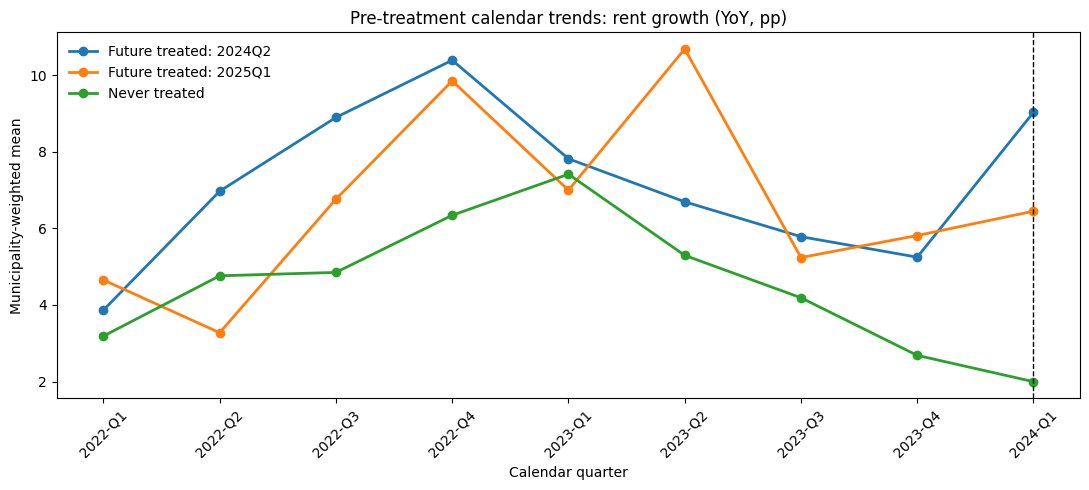

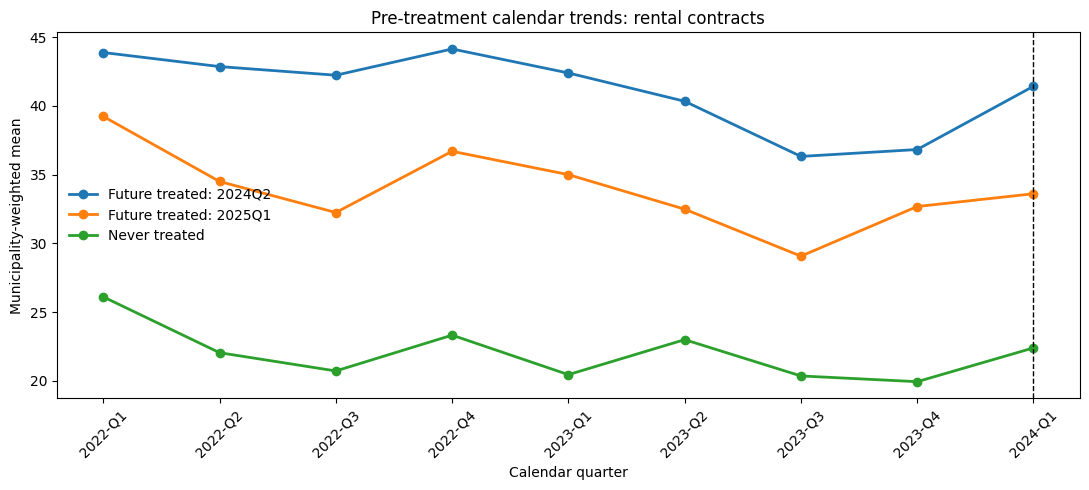

,group_label,period,time_index,outcome_price_growth
0,Future treated: 2024Q2,2022-Q1,8089,3.8663
9,Future treated: 2025Q1,2022-Q1,8089,4.6528
18,Never treated,2022-Q1,8089,3.1874
10,Future treated: 2025Q1,2022-Q2,8090,3.2755
19,Never treated,2022-Q2,8090,4.7625
1,Future treated: 2024Q2,2022-Q2,8090,6.9731
2,Future treated: 2024Q2,2022-Q3,8091,8.9006
11,Future treated: 2025Q1,2022-Q3,8091,6.7647
20,Never treated,2022-Q3,8091,4.8515
21,Never treated,2022-Q4,8092,6.3439


,group_label,period,time_index,outcome_market_activity
0,Future treated: 2024Q2,2022-Q1,8089,43.8726
9,Future treated: 2025Q1,2022-Q1,8089,39.2244
18,Never treated,2022-Q1,8089,26.1079
10,Future treated: 2025Q1,2022-Q2,8090,34.4958
19,Never treated,2022-Q2,8090,22.0487
1,Future treated: 2024Q2,2022-Q2,8090,42.8496
2,Future treated: 2024Q2,2022-Q3,8091,42.2219
11,Future treated: 2025Q1,2022-Q3,8091,32.2396
20,Never treated,2022-Q3,8091,20.7212
21,Never treated,2022-Q4,8092,23.3236


In [6]:
rent_calendar_df, fig_rent_cal = plot_calendar_means(
    rent_sample,
    "outcome_price_growth",
    "Pre-treatment calendar trends: rent growth (YoY, pp)",
    OUT_DIR / "parallel_trends_calendar_rent.png",
)
contracts_calendar_df, fig_contracts_cal = plot_calendar_means(
    contracts_sample,
    "outcome_market_activity",
    "Pre-treatment calendar trends: rental contracts",
    OUT_DIR / "parallel_trends_calendar_contracts.png",
)

plt.show()

display(rent_calendar_df.head(12))
display(contracts_calendar_df.head(12))

## 2. Lead-only pretrend event-study regressions

This is the formal parallel-trends diagnostic.

- Sample: **untreated observations only**
- Controls: **never-treated municipalities**
- Specification: municipality FE + period FE
- Reference period: **event_time = -1**

A valid design should show lead coefficients close to zero and a **joint p-value** that does not reject.

In [7]:
rent_pre_coeffs, rent_pre_summary, rent_support, rent_design, rent_model = run_pretrend_event_study(
    rent_sample,
    "outcome_price_growth",
    min_support=25,
)
contracts_pre_coeffs, contracts_pre_summary, contracts_support, contracts_design, contracts_model = run_pretrend_event_study(
    contracts_sample,
    "outcome_market_activity",
    min_support=25,
)

display(rent_pre_coeffs)
display(rent_pre_summary)
display(contracts_pre_coeffs)
display(contracts_pre_summary)

/home/venatio/documents/university/public-sector-2026/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/home/venatio/documents/university/public-sector-2026/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


,event_time,att,se,p_value,ci_low,ci_high,att_stars
0,-12,-2.0640,2.4409,0.3978,-6.8482,2.7201,-2.0640
1,-11,-5.7842,2.0125,0.0041,-9.7288,-1.8396,-5.7842***
2,-10,-1.7137,2.1825,0.4323,-5.9914,2.5640,-1.7137
3,-9,-2.1181,1.7588,0.2285,-5.5655,1.3292,-2.1181
4,-8,-2.7638,1.7458,0.1134,-6.1855,0.6579,-2.7638
5,-7,0.9757,1.9030,0.6082,-2.7541,4.7055,0.9757
6,-6,-1.7266,1.8567,0.3524,-5.3658,1.9126,-1.7266
7,-5,-1.7444,1.9665,0.3751,-5.5987,2.1100,-1.7444
8,-4,-1.6595,1.6908,0.3263,-4.9735,1.6544,-1.6595
9,-3,-2.8231,1.5847,0.0748,-5.9291,0.2829,-2.8231*


,Outcome,Joint test null,Wald statistic,p_value,N observations,N municipalities,Lead count,Reference period,Time FE,Municipality FE,Clustered SE
0,outcome_price_growth,All pre-treatment lead coefficients = 0,15.6175,0.1559,5916,528,11,event_time = -1,Yes,Yes,Municipality


,event_time,att,se,p_value,ci_low,ci_high,att_stars
0,-12,2.3861,1.9009,0.2094,-1.3397,6.1119,2.3861
1,-11,1.5796,1.6850,0.3485,-1.7230,4.8823,1.5796
2,-10,0.1898,1.6390,0.9078,-3.0228,3.4023,0.1898
3,-9,0.2762,1.3569,0.8387,-2.3832,2.9357,0.2762
4,-8,2.5129,1.1921,0.0350,0.1764,4.8495,2.5129**
5,-7,0.5249,1.2226,0.6677,-1.8714,2.9212,0.5249
6,-6,-0.3766,1.2427,0.7618,-2.8123,2.0590,-0.3766
7,-5,2.1475,1.1642,0.0651,-0.1342,4.4293,2.1475*
8,-4,-0.6682,0.9580,0.4855,-2.5458,1.2094,-0.6682
9,-3,-2.2800,1.2031,0.0581,-4.6382,0.0782,-2.2800*


,Outcome,Joint test null,Wald statistic,p_value,N observations,N municipalities,Lead count,Reference period,Time FE,Municipality FE,Clustered SE
0,outcome_market_activity,All pre-treatment lead coefficients = 0,35.9605,0.0002,10944,947,11,event_time = -1,Yes,Yes,Municipality


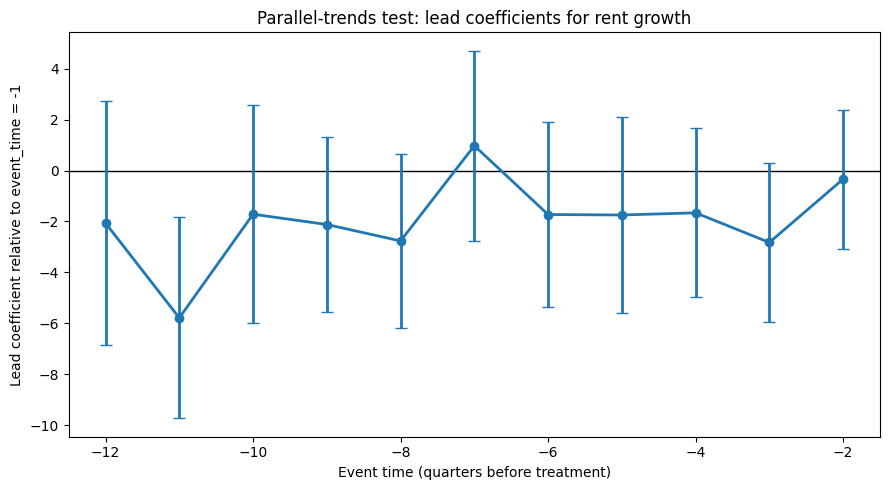

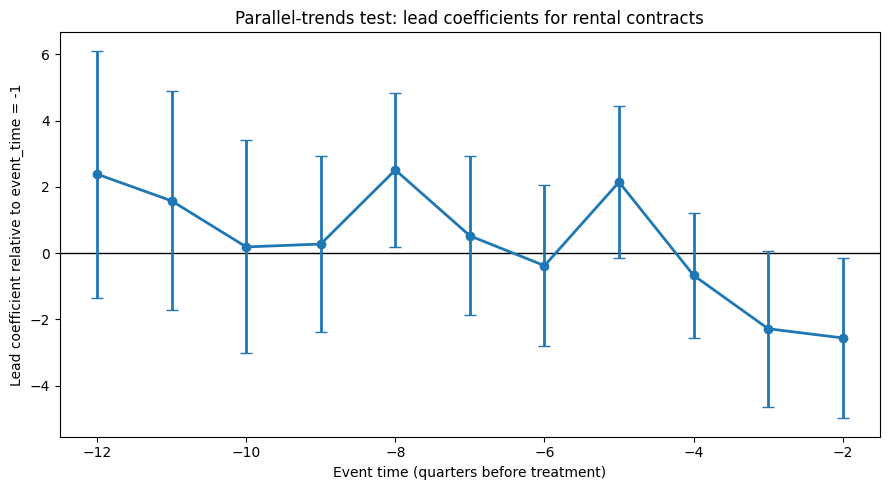

In [8]:
fig_rent_pre = plot_pretrend_event_study(
    rent_pre_coeffs,
    "Parallel-trends test: lead coefficients for rent growth",
    OUT_DIR / "parallel_trends_eventstudy_rent.png",
)

fig_contracts_pre = plot_pretrend_event_study(
    contracts_pre_coeffs,
    "Parallel-trends test: lead coefficients for rental contracts",
    OUT_DIR / "parallel_trends_eventstudy_contracts.png",
)

plt.show()

In [9]:
print("Support by negative event time: rent")
display(rent_support)

print("Support by negative event time: contracts")
display(contracts_support)

Support by negative event time: rent


,event_time,n_treated_municipalities
0,-12.0000,131
1,-11.0000,131
2,-10.0000,131
3,-9.0000,271
4,-8.0000,271
5,-7.0000,271
6,-6.0000,271
7,-5.0000,271
8,-4.0000,271
9,-3.0000,271


Support by negative event time: contracts


,event_time,n_treated_municipalities
0,-12.0000,131
1,-11.0000,131
2,-10.0000,131
3,-9.0000,271
4,-8.0000,271
5,-7.0000,271
6,-6.0000,271
7,-5.0000,271
8,-4.0000,271
9,-3.0000,271


## 3. Placebo DiD in the untreated pre-period

This is a simple robustness check.

- Window: **2022Q1–2024Q1**
- Fake treatment start: **2023Q1**
- Groups: future treated vs never treated
- Specification: municipality FE + period FE

If parallel trends are plausible, the placebo coefficient should be small and statistically insignificant.

In [10]:
rent_placebo, rent_placebo_sample, rent_placebo_model = run_placebo_did(
    rent_sample,
    "outcome_price_growth",
)
contracts_placebo, contracts_placebo_sample, contracts_placebo_model = run_placebo_did(
    contracts_sample,
    "outcome_market_activity",
)

display(rent_placebo)
display(contracts_placebo)

,Outcome,Placebo treatment starts,ATT_placebo,SE,p_value,ATT_placebo_stars,CI low,CI high,N observations,N municipalities,Time FE,Municipality FE,Clustered SE
0,outcome_price_growth,2023-Q1,0.5872,1.2588,0.6409,0.5872,-1.8800,3.0544,4752,528,Yes,Yes,Municipality


,Outcome,Placebo treatment starts,ATT_placebo,SE,p_value,ATT_placebo_stars,CI low,CI high,N observations,N municipalities,Time FE,Municipality FE,Clustered SE
0,outcome_market_activity,2023-Q1,-1.6468,0.8415,0.0504,-1.6468*,-3.2962,0.0026,8523,947,Yes,Yes,Municipality


## 4. Assemble summary tables

In [11]:
parallel_summary = pd.concat(
    [
        rent_pre_summary.assign(Test="Lead-only event-study"),
        contracts_pre_summary.assign(Test="Lead-only event-study"),
        rent_placebo.assign(Test="Placebo DiD"),
        contracts_placebo.assign(Test="Placebo DiD"),
    ],
    ignore_index=True,
    sort=False,
)

parallel_summary

,Outcome,Joint test null,Wald statistic,p_value,N observations,N municipalities,Lead count,Reference period,Time FE,Municipality FE,Clustered SE,Test,Placebo treatment starts,ATT_placebo,SE,ATT_placebo_stars,CI low,CI high
0,outcome_price_growth,All pre-treatment lead coefficients = 0,15.6175,0.1559,5916,528,11.0000,event_time = -1,Yes,Yes,Municipality,Lead-only event-study,NaN,NaN,NaN,NaN,NaN,NaN
1,outcome_market_activity,All pre-treatment lead coefficients = 0,35.9605,0.0002,10944,947,11.0000,event_time = -1,Yes,Yes,Municipality,Lead-only event-study,NaN,NaN,NaN,NaN,NaN,NaN
2,outcome_price_growth,NaN,NaN,0.6409,4752,528,NaN,NaN,Yes,Yes,Municipality,Placebo DiD,2023-Q1,0.5872,1.2588,0.5872,-1.8800,3.0544
3,outcome_market_activity,NaN,NaN,0.0504,8523,947,NaN,NaN,Yes,Yes,Municipality,Placebo DiD,2023-Q1,-1.6468,0.8415,-1.6468*,-3.2962,0.0026


In [12]:
rent_pre_coeffs_out = rent_pre_coeffs.copy()
rent_pre_coeffs_out.insert(0, "Outcome", "Rent growth (YoY, pp)")

contracts_pre_coeffs_out = contracts_pre_coeffs.copy()
contracts_pre_coeffs_out.insert(0, "Outcome", "Tenancy agreements per 10k")

pretrend_coeffs_out = pd.concat(
    [rent_pre_coeffs_out, contracts_pre_coeffs_out],
    ignore_index=True,
)

pretrend_coeffs_out

,Outcome,event_time,att,se,p_value,ci_low,ci_high,att_stars
0,"Rent growth (YoY, pp)",-12,-2.0640,2.4409,0.3978,-6.8482,2.7201,-2.0640
1,"Rent growth (YoY, pp)",-11,-5.7842,2.0125,0.0041,-9.7288,-1.8396,-5.7842***
2,"Rent growth (YoY, pp)",-10,-1.7137,2.1825,0.4323,-5.9914,2.5640,-1.7137
3,"Rent growth (YoY, pp)",-9,-2.1181,1.7588,0.2285,-5.5655,1.3292,-2.1181
4,"Rent growth (YoY, pp)",-8,-2.7638,1.7458,0.1134,-6.1855,0.6579,-2.7638
5,"Rent growth (YoY, pp)",-7,0.9757,1.9030,0.6082,-2.7541,4.7055,0.9757
6,"Rent growth (YoY, pp)",-6,-1.7266,1.8567,0.3524,-5.3658,1.9126,-1.7266
7,"Rent growth (YoY, pp)",-5,-1.7444,1.9665,0.3751,-5.5987,2.1100,-1.7444
8,"Rent growth (YoY, pp)",-4,-1.6595,1.6908,0.3263,-4.9735,1.6544,-1.6595
9,"Rent growth (YoY, pp)",-3,-2.8231,1.5847,0.0748,-5.9291,0.2829,-2.8231*


## 5. Save outputs

In [13]:
PRETREND_RENT_CSV = OUT_DIR / "parallel_trends_rent_pretrend_coeffs.csv"
PRETREND_CONTRACTS_CSV = OUT_DIR / "parallel_trends_contracts_pretrend_coeffs.csv"
PRETREND_ALL_CSV = OUT_DIR / "parallel_trends_pretrend_coeffs.csv"
SUMMARY_CSV = OUT_DIR / "parallel_trends_summary.csv"
SUMMARY_XLSX = OUT_DIR / "parallel_trends_summary.xlsx"
SUMMARY_TEX = OUT_DIR / "parallel_trends_summary.tex"

rent_pre_coeffs.to_csv(PRETREND_RENT_CSV, index=False)
contracts_pre_coeffs.to_csv(PRETREND_CONTRACTS_CSV, index=False)
pretrend_coeffs_out.to_csv(PRETREND_ALL_CSV, index=False)

parallel_summary.to_csv(SUMMARY_CSV, index=False)
parallel_summary.to_excel(SUMMARY_XLSX, index=False)
SUMMARY_TEX.write_text(parallel_summary.to_latex(index=False, escape=False, float_format="%.4f"), encoding="utf-8")

print("Saved:")
for p in [
    PRETREND_RENT_CSV,
    PRETREND_CONTRACTS_CSV,
    PRETREND_ALL_CSV,
    SUMMARY_CSV,
    SUMMARY_XLSX,
    SUMMARY_TEX,
    OUT_DIR / "parallel_trends_calendar_rent.png",
    OUT_DIR / "parallel_trends_calendar_contracts.png",
    OUT_DIR / "parallel_trends_eventstudy_rent.png",
    OUT_DIR / "parallel_trends_eventstudy_contracts.png",
]:
    print(" -", p)

Saved:
 - /home/venatio/documents/university/public-sector-2026/out/parallel_trends_rent_pretrend_coeffs.csv
 - /home/venatio/documents/university/public-sector-2026/out/parallel_trends_contracts_pretrend_coeffs.csv
 - /home/venatio/documents/university/public-sector-2026/out/parallel_trends_pretrend_coeffs.csv
 - /home/venatio/documents/university/public-sector-2026/out/parallel_trends_summary.csv
 - /home/venatio/documents/university/public-sector-2026/out/parallel_trends_summary.xlsx
 - /home/venatio/documents/university/public-sector-2026/out/parallel_trends_summary.tex
 - /home/venatio/documents/university/public-sector-2026/out/parallel_trends_calendar_rent.png
 - /home/venatio/documents/university/public-sector-2026/out/parallel_trends_calendar_contracts.png
 - /home/venatio/documents/university/public-sector-2026/out/parallel_trends_eventstudy_rent.png
 - /home/venatio/documents/university/public-sector-2026/out/parallel_trends_eventstudy_contracts.png
